# 04 Figures

Figures for the results chapter, drawn exclusively from the frozen tables in `results/` (written by
`03_gold.ipynb`); no database access. Each figure is saved to `results/figures/` as PNG (300 dpi) and SVG.
Below each figure: a proposed caption, the source table and the denominator of every share shown.

## Setup

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

RESULTS = Path("results")
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
CM = 1 / 2.54
WIDTH = 15 * CM  # printed width in the thesis

# Categorical slots of the validated reference palette, in fixed order (light mode).
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK_2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#ffffff"
OTHER = "#b5b4ad"                 # neutral grey for a folded "other" segment
SHADE = ("#efeee9", SURFACE)      # alternating period shading
PERIOD_LABELS = {"baseline_a": "baseline A", "campaign": "campaign", "post_election": "post-election",
                 "transition": "transition", "baseline_b": "baseline B"}
PERIODS = [("baseline_a", "2025-01-01", "2025-01-19"), ("campaign", "2025-01-20", "2025-02-23"),
           ("post_election", "2025-02-24", "2025-03-31"), ("transition", "2025-04-01", "2025-04-30"),
           ("baseline_b", "2025-05-01", "2025-06-30")]
ELECTION_DAY = pd.Timestamp("2025-02-23")

mpl.rcParams.update({
    "font.family": "Times New Roman", "font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 8, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.5, "axes.axisbelow": True, "lines.linewidth": 1.4, "legend.frameon": False,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": SURFACE, "svg.fonttype": "none",
    "figure.dpi": 110,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)


def save(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(FIG / f"{name}.{ext}")
    plt.show()


def read(name, **kw):
    return pd.read_csv(RESULTS / f"{name}.csv", **kw)

## Figure 1: weekly series, TikTok

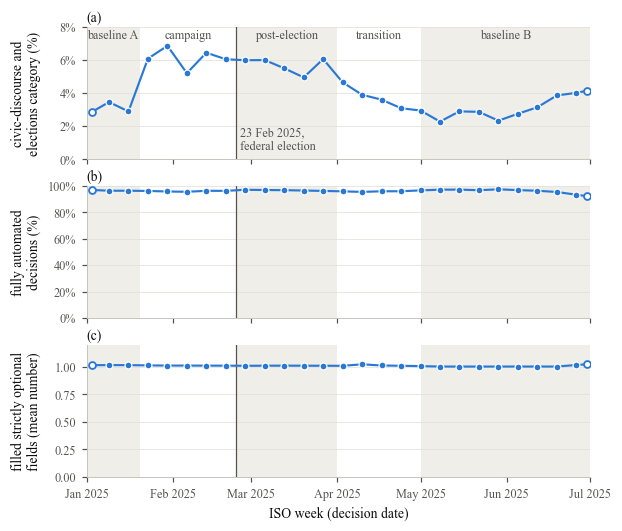

In [2]:
t5 = read("t05_weekly_election_share", parse_dates=["week_start"])
t7 = read("t07_weekly_automation_share", parse_dates=["week_start"])
t8 = read("t08_weekly_granularity", parse_dates=["week_start"])
keys = ["platform", "week_start"]
w = (t5.merge(t7[keys + ["share_fully_automated"]], on=keys)
       .merge(t8[keys + ["mean_n_filled_strictly_optional"]], on=keys))
w = w[w.platform == "TikTok"].copy()

# plot each week at the midpoint of its days inside the window, so points align with the period shading
lo, hi = pd.Timestamp(PERIODS[0][1]), pd.Timestamp(PERIODS[-1][2])
start = w["week_start"].clip(lower=lo)
end = (w["week_start"] + pd.Timedelta(days=6)).clip(upper=hi)
w["x"] = start + (end - start) / 2
full, part = w[w.days_in_window == 7], w[w.days_in_window < 7]

panels = [("share_election", "civic-discourse and\nelections category (%)", (0, 0.08), PCT),
          ("share_fully_automated", "fully automated\ndecisions (%)", (0, 1.0), PCT),
          ("mean_n_filled_strictly_optional", "filled strictly optional\nfields (mean number)", (0, 1.2), None)]
fig, axes = plt.subplots(3, 1, figsize=(WIDTH, 13.5 * CM), sharex=True)
for ax, (col, label, ylim, fmt), letter in zip(axes, panels, "abc"):
    for k, (p, a, b) in enumerate(PERIODS):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=SHADE[k % 2], lw=0, zorder=0)
    ax.axvline(ELECTION_DAY + pd.Timedelta(hours=12), color=INK_2, lw=0.8, zorder=1)
    ax.plot(w["x"], w[col], color=BLUE, lw=1.4, zorder=2)
    ax.plot(full["x"], full[col], "o", ms=4.5, color=BLUE, mec=SURFACE, mew=0.8, zorder=3)
    ax.plot(part["x"], part[col], "o", ms=4.5, mfc=SURFACE, mec=BLUE, mew=1.2, zorder=3)
    ax.set_ylim(*ylim)
    ax.set_ylabel(label)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)
    ax.grid(axis="x", visible=False)
    ax.text(0.0, 1.02, f"({letter})", transform=ax.transAxes, va="bottom", fontsize=9)

top = axes[0]
for p, a, b in PERIODS:
    mid = pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a) + pd.Timedelta(days=1)) / 2
    top.text(mid, 0.0785, PERIOD_LABELS[p], ha="center", va="top", fontsize=8, color=INK_2)
top.text(ELECTION_DAY + pd.Timedelta(days=2), 0.004, "23 Feb 2025,\nfederal election", fontsize=8,
         color=INK_2, va="bottom")
axes[-1].set_xlim(lo, hi + pd.Timedelta(days=1))
axes[-1].xaxis.set_major_locator(mpl.dates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("ISO week (decision date)")
fig.align_ylabels(axes)
save(fig, "figure1_tiktok_weekly_series")

**Proposed caption.** Figure 1: Weekly share of the civic-discourse and elections category (a), share of
fully automated decisions (b) and mean number of filled strictly optional fields (c) in TikTok statements
of reasons, January to June 2025 (own illustration, data: DSA Transparency Database).

- Source: `results/t05_weekly_election_share.csv`, `results/t07_weekly_automation_share.csv`,
  `results/t08_weekly_granularity.csv`.
- Denominator: all TikTok statements of the analysis set decided in the respective ISO week (`n_total`,
  15.5 to 45.7 million per full week).
- Note: weeks are placed at the midpoint of their days within 1 January to 30 June 2025. Hollow markers:
  the two weeks with fewer than seven days in the window (week of 30 December 2024, five days; week of
  30 June 2025, one day). Shading marks the five periods. X is not plotted because it reports no
  statement in the civic-discourse and elections category.

## Figure 2: fully automated decisions on TikTok, by category and by content type

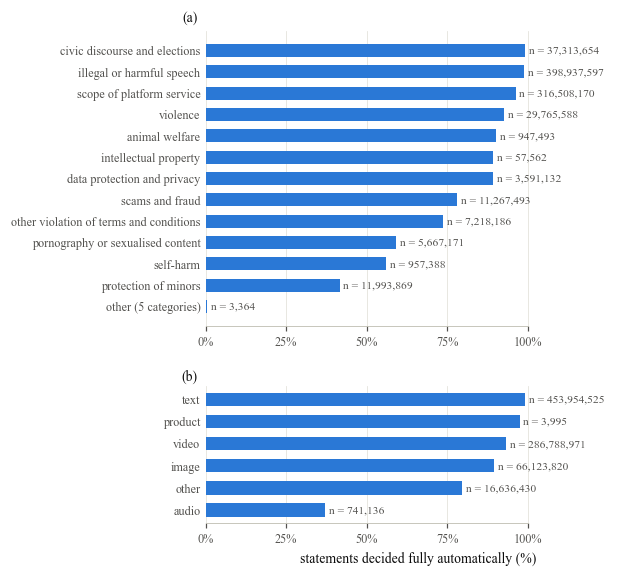

In [3]:
CATEGORY_NAMES = {
    "STATEMENT_CATEGORY_ILLEGAL_OR_HARMFUL_SPEECH": "illegal or harmful speech",
    "STATEMENT_CATEGORY_SCOPE_OF_PLATFORM_SERVICE": "scope of platform service",
    "STATEMENT_CATEGORY_NEGATIVE_EFFECTS_ON_CIVIC_DISCOURSE_OR_ELECTIONS": "civic discourse and elections",
    "STATEMENT_CATEGORY_VIOLENCE": "violence",
    "STATEMENT_CATEGORY_PROTECTION_OF_MINORS": "protection of minors",
    "STATEMENT_CATEGORY_SCAMS_AND_FRAUD": "scams and fraud",
    "STATEMENT_CATEGORY_OTHER_VIOLATION_TC": "other violation of terms and conditions",
    "STATEMENT_CATEGORY_PORNOGRAPHY_OR_SEXUALIZED_CONTENT": "pornography or sexualised content",
    "STATEMENT_CATEGORY_DATA_PROTECTION_AND_PRIVACY_VIOLATIONS": "data protection and privacy",
    "STATEMENT_CATEGORY_SELF_HARM": "self-harm",
    "STATEMENT_CATEGORY_ANIMAL_WELFARE": "animal welfare",
    "STATEMENT_CATEGORY_INTELLECTUAL_PROPERTY_INFRINGEMENTS": "intellectual property",
}
t10 = read("t10_automation_by_category")
c = t10[t10.platform == "TikTok"].copy()
small = c[c.n_rows < 2000]
c = pd.concat([c[c.n_rows >= 2000],
               pd.DataFrame([{"category": f"other ({len(small)} categories)", "n_rows": small.n_rows.sum(),
                              "AUTOMATED_DECISION_FULLY": small.AUTOMATED_DECISION_FULLY.sum()}])])
c["label"] = c["category"].map(CATEGORY_NAMES).fillna(c["category"])
c["share"] = c["AUTOMATED_DECISION_FULLY"] / c["n_rows"]

t3 = read("t03_tiktok_automation_by_content_type")
t3["label"] = t3["content_type"].str.removeprefix("CONTENT_TYPE_").str.lower()
t3["share"] = t3["AUTOMATED_DECISION_FULLY"] / t3["n_rows"]

fig, axes = plt.subplots(2, 1, figsize=(WIDTH, 13.5 * CM), height_ratios=[len(c), len(t3)])
for ax, d, letter in zip(axes, (c, t3), "ab"):
    d = d.sort_values("share")
    y = range(len(d))
    ax.barh(y, d["share"], height=0.6, color=BLUE)
    for yi, (s, n) in zip(y, zip(d["share"], d["n_rows"])):
        ax.text(s + 0.012, yi, f"n = {int(n):,}", va="center", fontsize=7.5, color=INK_2)
    ax.set_yticks(list(y), d["label"])
    ax.set_xlim(0, 1.32)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.xaxis.set_major_formatter(PCT)
    ax.spines["bottom"].set_bounds(0, 1)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.text(-0.02, 1.02, f"({letter})", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
axes[-1].set_xlabel("statements decided fully automatically (%)")
fig.tight_layout(h_pad=1.5)
save(fig, "figure2_tiktok_automation")

**Proposed caption.** Figure 2: Share of TikTok statements of reasons decided fully automatically, by
category (a) and by content type (b), January to June 2025 (own illustration, data: DSA Transparency
Database).

- Source: `results/t10_automation_by_category.csv` (a), `results/t03_tiktok_automation_by_content_type.csv` (b).
- Denominator: the statements of each category (a) or content type (b), printed beside each bar.
- Note: "other (5 categories)" combines non-consensual behaviour (1,701), risk for public security
  (1,159), unsafe and illegal products (250), cyber violence (216) and unsafe and prohibited products
  (38), together 3,364 statements. In (b) a statement listing several content types is counted once per
  type.

## Figure 3: hardest measure per statement, TikTok and X

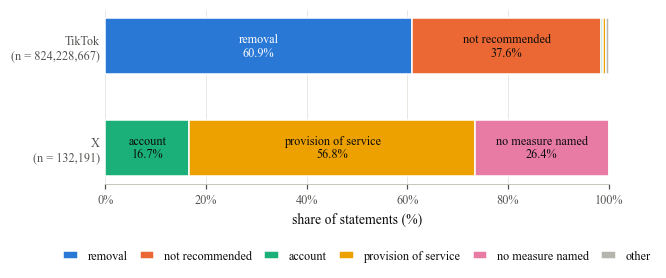

platform              TikTok       X
segment                             
account                0.441  16.733
no measure named       0.001  26.444
not recommended       37.609   0.000
other                  0.533   0.032
provision of service   0.506  56.791
removal               60.911   0.000


In [4]:
t1d = read("t01d_measure_types")
t1d2 = read("t01d2_action_classes")
SEGMENTS = [("removal", BLUE, SURFACE), ("not recommended", ORANGE, INK), ("account", AQUA, INK),
            ("provision of service", YELLOW, INK), ("no measure named", MAGENTA, INK),
            ("other", OTHER, INK)]


def segment(row):
    if row.action_class == "content removed":
        return "removal"
    if row.action_class in ("not recommended in feed", "not recommended in feed and search"):
        return "not recommended"
    if row.measure_type in ("account", "provision of service", "no measure named"):
        return row.measure_type
    return "other"


t1d2["segment"] = t1d2.apply(segment, axis=1)
seg = t1d2.groupby(["platform", "segment"])["n"].sum().unstack(fill_value=0)
total = t1d.groupby("platform")["n"].sum()
assert (seg.sum(axis=1) == total).all()
share = seg.div(total, axis=0)

order = ["X", "TikTok"]  # TikTok on top
fig, ax = plt.subplots(figsize=(WIDTH, 5.2 * CM))
for yi, plat in enumerate(order):
    left = 0.0
    for name, color, text_color in SEGMENTS:
        v = share.loc[plat].get(name, 0.0)
        if v <= 0:
            continue
        ax.barh(yi, v, left=left, height=0.55, color=color, edgecolor=SURFACE, linewidth=1.0,
                label=name if yi == 1 or name in ("account", "provision of service", "no measure named") else None)
        if v >= 0.03:
            ax.text(left + v / 2, yi, f"{name}\n{100 * v:.1f}%", ha="center", va="center", fontsize=8,
                    color=text_color)
        left += v
ax.set_yticks([0, 1], [f"X\n(n = {total['X']:,})", f"TikTok\n(n = {total['TikTok']:,})"])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("share of statements (%)")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend([by_label[n] for n, _, _ in SEGMENTS if n in by_label], [n for n, _, _ in SEGMENTS if n in by_label],
          ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.32), handlelength=1.2, columnspacing=1.0)
save(fig, "figure3_hardest_measure")
print((share * 100).round(3).T)

**Proposed caption.** Figure 3: Hardest measure per statement of reasons, TikTok and X, January to June
2025 (own illustration, data: DSA Transparency Database).

- Source: `results/t01d_measure_types.csv`, `results/t01d2_action_classes.csv`.
- Denominator: all statements of the platform in the analysis set (TikTok 824,228,667; X 132,191).
- Note: where a statement carries several restriction types, only the hardest is counted (account,
  monetary, provision of service, visibility). TikTok's visibility measures are split into removal and
  non-recommendation (in the feed, or in the feed and in search). Segments below 3%: TikTok account
  0.44%, provision of service 0.51%, no measure named 0.0006% and other 0.53% (age restriction 0.41%,
  advertisement not published 0.09%, unspecified 0.03%, content disabled 0.003%, monetary 0.0005%,
  review removed or hidden 0.000001%); X other 0.03% (unspecified 0.027%, annotation added 0.005%).
  X reports no removal and no non-recommendation.

## Figure 4: fill rate of each optional field, TikTok and X

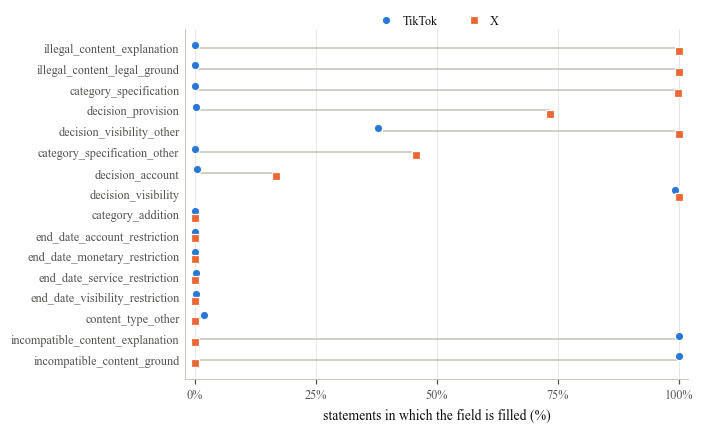

left out (empty on both platforms): account_type, content_language, decision_ground_reference_url, decision_monetary, incompatible_content_illegal, source_identity, decision_monetary_other


In [5]:
t4 = read("t04b_fill_rates")
empty = t4[(t4.TikTok_fill_rate == 0) & (t4.X_fill_rate == 0)]["attribute"].tolist()
d = t4[~t4.attribute.isin(empty)].copy()
d["diff"] = d["X_fill_rate"] - d["TikTok_fill_rate"]
d = d.sort_values("diff").reset_index(drop=True)  # TikTok-dominated at the bottom, X-dominated at the top

fig, ax = plt.subplots(figsize=(WIDTH, 10.5 * CM))
y = range(len(d))
ax.hlines(y, d[["TikTok_fill_rate", "X_fill_rate"]].min(axis=1), d[["TikTok_fill_rate", "X_fill_rate"]].max(axis=1),
          color=AXIS, lw=1.0, zorder=1)
DODGE = 0.16  # TikTok slightly above, X slightly below the row line, so equal values stay visible
ax.plot(d["TikTok_fill_rate"], [v + DODGE for v in y], "o", ms=5.5, color=BLUE, mec=SURFACE, mew=0.8,
        zorder=3, label="TikTok", clip_on=False)
ax.plot(d["X_fill_rate"], [v - DODGE for v in y], "s", ms=5.0, color=ORANGE, mec=SURFACE, mew=0.8,
        zorder=3, label="X", clip_on=False)
ax.set_yticks(list(y), d["attribute"], fontsize=8)
ax.set_xlim(-0.02, 1.02)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("statements in which the field is filled (%)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.07), ncol=2, handletextpad=0.3)
save(fig, "figure4_fill_rates")
print("left out (empty on both platforms):", ", ".join(empty))

**Proposed caption.** Figure 4: Share of statements of reasons in which each optional field is filled,
TikTok and X, January to June 2025 (own illustration, data: DSA Transparency Database).

- Source: `results/t04b_fill_rates.csv`.
- Denominator: all statements of the platform in the analysis set (TikTok 824,228,667; X 132,191).
- Note: rows are sorted by the difference between X and TikTok. Not shown are the six optional fields
  that neither platform fills: `account_type`, `content_language`, `decision_ground_reference_url`,
  `decision_monetary_other`, `incompatible_content_illegal`, `source_identity`.

## Figure 5: share of the category within TikTok image moderation, by period

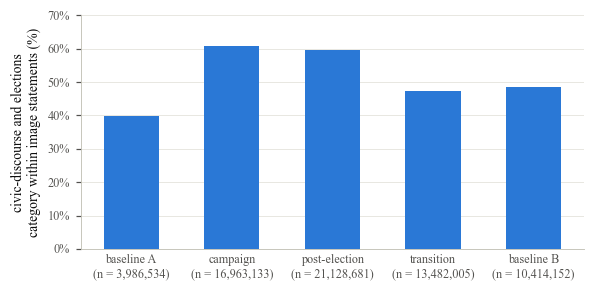

                 n_type  n_election  election_share_within_type
period                                                         
baseline_a      3986534     1593548                    0.399733
campaign       16963133    10326181                    0.608743
post_election  21128681    12582407                    0.595513
transition     13482005     6363523                    0.472001
baseline_b     10414152     5042910                    0.484236


In [6]:
t12 = read("t12_election_by_content_type")
img = t12[t12.content_type == "CONTENT_TYPE_IMAGE"].set_index("period").loc[[p for p, _, _ in PERIODS]]

fig, ax = plt.subplots(figsize=(WIDTH, 7 * CM))
x = range(len(img))
ax.bar(x, img["election_share_within_type"], width=0.55, color=BLUE)
ax.set_xticks(list(x), [f"{PERIOD_LABELS[p]}\n(n = {int(n):,})" for p, n in zip(img.index, img["n_type"])])
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel("civic-discourse and elections\ncategory within image statements (%)")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", length=0)
save(fig, "figure5_category_within_image")
print((img[["n_type", "n_election", "election_share_within_type"]]))

**Proposed caption.** Figure 5: Share of the civic-discourse and elections category among TikTok
statements of reasons on image content, by period, January to June 2025 (own illustration, data: DSA
Transparency Database).

- Source: `results/t12_election_by_content_type.csv`.
- Denominator: TikTok statements on image content decided in the period (`n_type`, printed under each
  bar); a statement listing several content types is counted once per type.
- Note: the corresponding shares within text (at most 0.02%) and video (at most 0.82%) are too small to
  plot on the same scale.